# Proyecto 2 - Análisis exploratorio del dataset Diabetes 130-US hospitals

Este notebook documenta las decisiones de limpieza, ingeniería de características y
partición que implementa el DAG `diabetes_pipeline` (`airflow/dags/diabetes/`).
Las transformaciones se importan del mismo paquete del DAG, así lo que se analiza aquí
es exactamente lo que corre en Airflow.

Ejecución local:

```bash
cd proyecto_2/notebooks
uv run --with pandas,pyarrow,matplotlib,scikit-learn==1.9.1,requests,jupyterlab jupyter lab
```

In [2]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

sys.path.insert(0, str(Path.cwd().parent / "airflow" / "dags"))
from diabetes import config
from diabetes.preprocessing import clean_batch, diag_group, row_hash, validate_batch

pd.set_option("display.max_columns", 60)

## 1. Carga del dataset

Se descarga una sola vez desde la URL del enunciado a `notebooks/data/Diabetes.csv`.

In [4]:
!ls

data      eda.ipynb


In [7]:
#data_path = Path("data/Diabetes.csv")
data_path = Path("/Users/crissebasbol_x/Private/others/Javeriana/mlops/mlops-course/proyecto_2/notebooks/data/Diabetes.csv")
#data_path.parent.mkdir(exist_ok=True)
#if not data_path.exists():
#    r = requests.get(config.SOURCE_URL, allow_redirects=True, stream=True, timeout=300)
#    r.raise_for_status()
#    data_path.write_bytes(r.content)

raw = pd.read_csv(data_path, dtype=str, keep_default_na=False)
print(raw.shape)
raw.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


Se lee todo como texto y sin convertir `?` ni `None` a nulos: así queda en la capa **raw**
(sin transformaciones destructivas). `None` en `max_glu_serum` y `A1Cresult` significa
"prueba no realizada", no un dato faltante.

In [8]:
assert list(raw.columns) == config.SOURCE_COLUMNS
missing = pd.DataFrame({
    "pct_interrogacion": (raw == "?").mean() * 100,
    "pct_vacio": (raw == "").mean() * 100,
    "valores_distintos": raw.nunique(),
}).sort_values("pct_interrogacion", ascending=False)
missing.head(15)

,pct_interrogacion,pct_vacio,valores_distintos
weight,96.858479,0.0,10
medical_specialty,49.082208,0.0,73
payer_code,39.557416,0.0,18
race,2.233555,0.0,6
diag_3,1.398306,0.0,790
diag_2,0.351787,0.0,749
diag_1,0.020636,0.0,717
encounter_id,0.000000,0.0,101766
tolazamide,0.000000,0.0,3
glyburide,0.000000,0.0,4


**Decisiones sobre faltantes:**

- `weight` (~97 % `?`) y `payer_code` (~40 % `?`, administrativo) se **eliminan**.
- `medical_specialty` (~49 % `?`): se conserva; `?` pasa a `Unknown` y las especialidades
  fuera del top 9 se agrupan en `Other`.
- `race` (~2 % `?`) y `diag_1/2/3` (< 2 %): `?` pasa a la categoría `Unknown`. No se imputan
  con la moda para no inventar información clínica.

## 2. Variable objetivo

,pct
readmitted,
NO,53.91
>30,34.93
<30,11.16


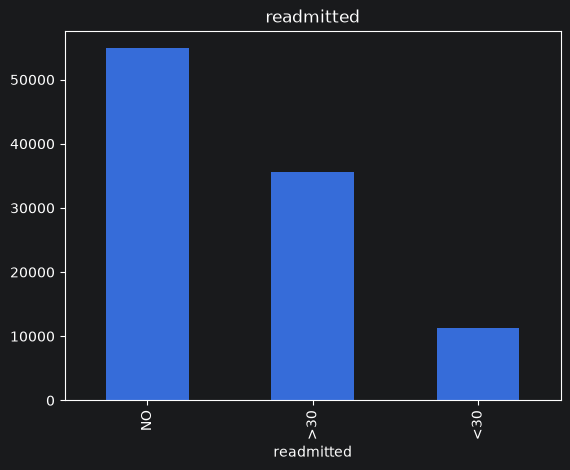

In [9]:
target = raw["readmitted"].value_counts()
display((target / len(raw) * 100).round(2).to_frame("pct"))
target.plot.bar(title="readmitted")
plt.show()

Problema **multiclase desbalanceado**: `NO` ~54 %, `>30` ~35 %, `<30` ~11 %.

**Métrica principal: F1 macro.** Promedia el F1 de cada clase con el mismo peso, así la
readmisión temprana (`<30`, la minoritaria y la más costosa clínicamente) pesa igual que
`NO`. Accuracy es engañosa: predecir siempre `NO` daría ~54 %. Se reportan también recall y
F1 por clase (en especial `recall_early_readmission`), F1 weighted y ROC-AUC one-vs-rest.
Los modelos usan `class_weight="balanced"`.

## 3. Identificadores y fuga de información

In [10]:
print("encounter_id únicos:", raw["encounter_id"].is_unique)
per_patient = raw["patient_nbr"].value_counts()
print("pacientes:", len(per_patient), "| con más de un encuentro:", (per_patient > 1).sum())
per_patient.describe()

encounter_id únicos: True
pacientes: 71518 | con más de un encuentro: 16773


count    71518.000000
mean         1.422942
std          1.090740
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
Name: count, dtype: float64

Un paciente puede tener varios encuentros. Si sus encuentros quedan repartidos entre train y
test el modelo "memoriza" al paciente. Por eso el split se hace **por paciente**:
`md5(patient_nbr) % 100` (70 train / 15 val / 15 test). Es determinístico, así cada fila cae
siempre en el mismo conjunto en todas las ejecuciones incrementales del DAG.
`encounter_id` y `patient_nbr` se guardan en clean como referencia pero **no son features**.

## 4. Disposición al alta: exclusión de fallecidos y hospicio

In [12]:
excluded = raw["discharge_disposition_id"].isin(config.DISCHARGE_EXCLUDED)
print(f"Excluidos: {excluded.sum()} ({excluded.mean():.2%})")
pd.crosstab(raw["discharge_disposition_id"], raw["readmitted"]).reindex(sorted(config.DISCHARGE_EXCLUDED, key=int), fill_value=0)

Excluidos: 2423 (2.38%)


readmitted,<30,>30,NO
discharge_disposition_id,,,
11,0,0,1642
13,19,36,344
14,24,7,341
19,0,0,8
20,0,0,2
21,0,0,0


Los IDs 11, 19, 20, 21 (fallecido) y 13, 14 (hospicio) no pueden ser readmitidos: son ruido
para el objetivo. Se marcan `status='excluded'` en raw y no pasan a clean. Los demás IDs
de admisión, alta y origen se agrupan en categorías legibles (ver `config.py`).

## 5. Diagnósticos (ICD-9)

In [13]:
for col in ["diag_1", "diag_2", "diag_3"]:
    print(col, raw[col].nunique(), "códigos")
raw["diag_1"].map(diag_group).value_counts()

diag_1 717 códigos
diag_2 749 códigos
diag_3 790 códigos


diag_1
Circulatory        30437
Other              18172
Respiratory        14423
Digestive           9475
Diabetes            8757
Injury              6974
Genitourinary       5117
Musculoskeletal     4957
Neoplasms           3433
Unknown               21
Name: count, dtype: int64

Con 700+ códigos por columna un one-hot sería enorme y disperso. Se agrupan en 9 categorías
clínicas (Strack et al., 2014): Circulatory, Respiratory, Digestive, Diabetes, Injury,
Musculoskeletal, Genitourinary, Neoplasms y Other (incluye códigos V/E), más Unknown.

## 6. Medicamentos

In [14]:
renamed = raw.rename(columns=config.sql_name)
usage = (renamed[config.DIABETES_MEDS] != "No").mean().sort_values(ascending=False) * 100
usage.round(2).to_frame("pct_pacientes_con_el_medicamento")

,pct_pacientes_con_el_medicamento
insulin,53.44
metformin,19.64
glipizide,12.47
glyburide,10.47
pioglitazone,7.20
rosiglitazone,6.25
glimepiride,5.10
repaglinide,1.51
glyburide_metformin,0.69
nateglinide,0.69


De los 23 medicamentos, solo 7 tienen uso relevante (metformin, insulin, glipizide, glyburide,
pioglitazone, rosiglitazone, glimepiride); se conservan como categóricas (`No/Steady/Up/Down`).
Los demás tienen > 99 % `No` (varianza casi nula; `examide` y `citoglipton` son constantes) y se
resumen en dos features nuevas sobre los 23:

- `diabetes_meds_active`: cuántos medicamentos para diabetes recibe el paciente.
- `diabetes_meds_changed`: a cuántos se les subió o bajó la dosis.

## 7. Variables numéricas

In [15]:
numeric = [c for c in config.INTEGER_COLUMNS if c not in ("encounter_id", "patient_nbr")]
num = raw[numeric].astype(int)
display(num.describe().T)
num.join(raw["readmitted"]).groupby("readmitted").mean().T

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


readmitted,<30,>30,NO
time_in_hospital,4.768249,4.495541,4.254429
num_lab_procedures,44.226028,43.836601,42.381598
num_procedures,1.280884,1.249599,1.410305
num_medications,16.903143,16.282768,15.670367
number_outpatient,0.436911,0.496329,0.273112
number_emergency,0.357313,0.283669,0.109216
number_inpatient,1.224003,0.838993,0.381963
number_diagnoses,7.692789,7.646898,7.221366


Las numéricas no tienen faltantes y sus rangos son plausibles (p. ej. `time_in_hospital` entre
1 y 14 por definición del dataset). `number_inpatient` y `number_emergency` crecen con la
readmisión: buenas candidatas. Se escalan con `StandardScaler` dentro del Pipeline. `age`
viene en rangos de 10 años y se codifica como **ordinal** (`OrdinalEncoder` con el orden de
los rangos).

## 8. Validación y limpieza con el código del DAG

In [16]:
df = renamed.copy()
df["row_hash"] = [row_hash(list(v)) for v in df[config.RAW_COLUMNS].itertuples(index=False, name=None)]
df["batch_id"] = 0

valid, rejected = validate_batch(df)
print("válidas:", len(valid), "| rechazadas:", len(rejected))
pd.Series(rejected).value_counts().head()

válidas: 0 | rechazadas: 101766


gender con valor no permitido: Unknown/Invalid    3
Name: count, dtype: int64

In [17]:
clean, excluded_hashes = clean_batch(df[df["row_hash"].isin(valid)])
print(clean.shape, "excluidas:", len(excluded_hashes))
clean.head()

(0, 38) excluidas: 0


,row_hash,batch_id,encounter_id,patient_nbr,split,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetes_meds_active,diabetes_meds_changed,age,race,gender,admission_type,discharge_disposition,admission_source,medical_specialty,diag_1_group,diag_2_group,diag_3_group,max_glu_serum,a1cresult,metformin,glipizide,glyburide,pioglitazone,rosiglitazone,glimepiride,insulin,change,diabetesmed,readmitted,target


In [18]:
pd.crosstab(clean["split"], clean["readmitted"], normalize="index").round(3)

readmitted
split


Las rechazadas son las 3 filas con `gender = Unknown/Invalid`. La proporción de clases es
similar en train, val y test gracias al split por hash de paciente.

## 9. Resumen de la capa clean

| Tipo | Columnas | Tratamiento en el Pipeline |
|---|---|---|
| Numéricas | `time_in_hospital`, `num_lab_procedures`, `num_procedures`, `num_medications`, `number_outpatient`, `number_emergency`, `number_inpatient`, `number_diagnoses`, `diabetes_meds_active`, `diabetes_meds_changed` | `StandardScaler` |
| Ordinal | `age` | `OrdinalEncoder` (orden de rangos) |
| Categóricas | `race`, `gender`, `admission_type`, `discharge_disposition`, `admission_source`, `medical_specialty`, `diag_1/2/3_group`, `max_glu_serum`, `a1cresult`, 7 medicamentos, `change`, `diabetesmed` | `OneHotEncoder(handle_unknown="ignore")` |
| Eliminadas | `weight`, `payer_code`, 16 medicamentos poco usados (resumidos en los conteos), IDs | - |

La codificación vive dentro del Pipeline de sklearn registrado en MLflow; la API recibe las
columnas de clean y aplica la misma transformación, sin riesgo de diferencias entre
entrenamiento e inferencia.